In [1]:
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pathlib import Path
from dask.distributed import Client
import sys, os
from datetime import datetime, timedelta

from scores.spatial import fss_2d
from skimage.metrics import structural_similarity as ssim

import warnings
warnings.filterwarnings("ignore")

sys.path.append("/home/548/cd3022/repos/nowcast-evaluation/src")
import nowcast_preprocess

In [2]:
client = Client(
    n_workers=24,
    threads_per_worker=1
)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/36465/status,
Dashboard: /proxy/36465/status,Workers: 24
Total threads: 24,Total memory: 95.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:44413,Workers: 0
Dashboard: /proxy/36465/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:41035,Total threads: 1
Dashboard: /proxy/35833/status,Memory: 3.96 GiB
Nanny: tcp://127.0.0.1:36003,


In [3]:
YEAR = "2025"
MONTH = "01"
DAY = "01"

In [18]:
def preprocess_dit(ds):
    ds = nowcast_preprocess.preprocess_nowcast_dataset(
        ds,
        f_dim_name="lead_time",
        new_f_dim_name="lead_time",
    )
    return ds[["surface_global_irradiance"]].mean(dim=["member"])

dit_path = Path(f"/scratch/er8/cd3022/CPDiT/inference/{YEAR}/{MONTH}/{DAY}")
dit_files = sorted([f for f in dit_path.glob("*.nc")])

dit = xr.open_mfdataset(
    dit_files,
    preprocess = preprocess_dit,
    concat_dim='time',
    combine='nested',
    data_vars='minimal',
    coords='minimal',
    compat='override',
    parallel=True,
    chunks='auto'
)

In [19]:
lat_min = dit.latitude.min().item()
lat_max = dit.latitude.max().item()
lon_min = dit.longitude.min().item()
lon_max = dit.longitude.max().item()

In [20]:
def preprocess_gso_of(ds):
    ds = nowcast_preprocess.preprocess_nowcast_dataset(
        ds,
        f_dim_name="time",
        new_f_dim_name="lead_time",
        relative_leadtime=True
    )
    return ds.sel(
        latitude=slice(lat_max, lat_min),
        longitude=slice(lon_min, lon_max)
    )[["surface_global_irradiance"]]

gso_of_path = Path(f"/g/data/er8/nowcasts/nwc_20240701_20251231/{YEAR}/{MONTH}/{DAY}")
gso_of_files = sorted([f for f in gso_of_path.rglob("*.nc")])
gso_of = xr.open_mfdataset(
    gso_of_files,
    preprocess = preprocess_gso_of,
    concat_dim='time',
    combine='nested',
    data_vars='minimal',
    coords='minimal',
    compat='override',
    parallel=True,
    chunks='auto'
)


def preprocess_truth(ds):
    return ds.sel(
        latitude=slice(lat_min, lat_max),
        longitude=slice(lon_min, lon_max)
    )[["surface_global_irradiance"]]


truth_path = Path(f"/g/data/rv74/satellite-products/arc/der/himawari-ahi/solar/p1s/latest/{YEAR}/{MONTH}/{DAY}")
truth_files = sorted([f for f in truth_path.rglob("*.nc")])
truth = xr.open_mfdataset(
    truth_files,
    preprocess = preprocess_truth,
    concat_dim='time',
    combine='nested',
    data_vars='minimal',
    coords='minimal',
    compat='override',
    parallel=True,
    chunks='auto'
)

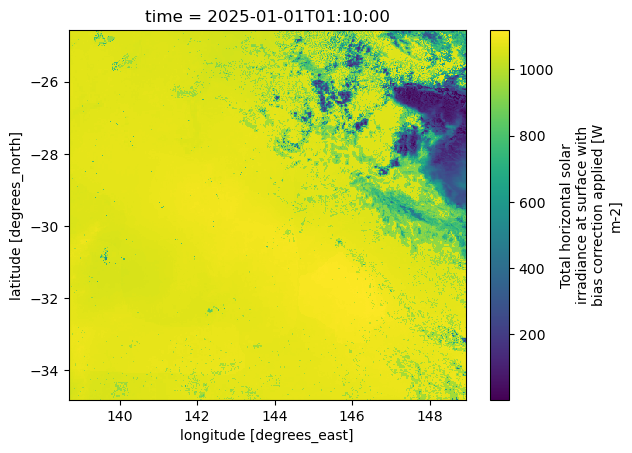

In [30]:
truth.isel(time=40).surface_global_irradiance.plot()

In [36]:
truth.sel(time=pd.Timestamp("2025-01-01T01:10"))

<xarray.Dataset> Size: 2MB
Dimensions:                    (latitude: 512, longitude: 512)
Coordinates:
  * latitude                   (latitude) float32 2kB -34.8 -34.78 ... -24.58
  * longitude                  (longitude) float32 2kB 138.7 138.7 ... 148.9
    time                       datetime64[ns] 8B 2025-01-01T01:10:00
Data variables:
    surface_global_irradiance  (latitude, longitude) float64 2MB dask.array<chunksize=(512, 512), meta=np.ndarray>
Attributes: (12/57)
    Conventions:                      CF-1.7
    Metadata_Conventions:             Unidata Dataset Discovery v1.0
    acknowledgment:                   The following acknowledgement is requir...
    cdm_data_type:                    grid
    comment:                          Solar radiation data derived from satel...
    contributor_name:                 Mines ParisTech; Commonwealth of Austra...
    ...                               ...
    date_created:                     20250325T033438Z
    bias_correction_applied:          1
    bias_correction_applied_meaning:  0: not applied; 1:applied
    quality:                          0
    quality_meaning:                  0: no_known_issues 1: known_issue 
    history:                          heliosat-4; post_process_p1s.py

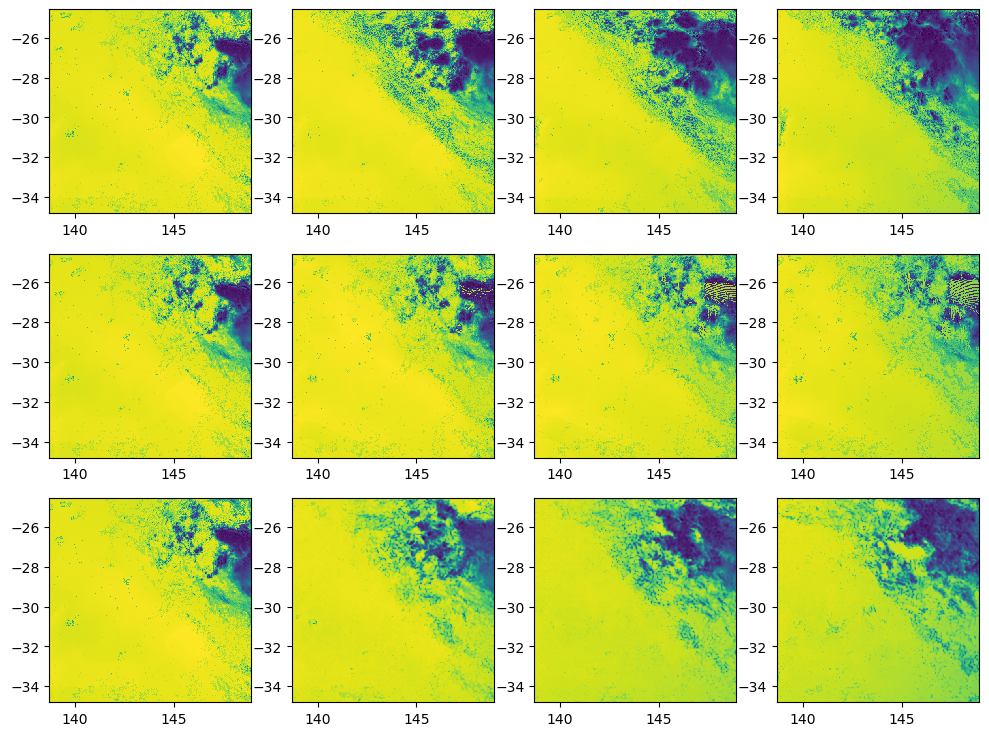

In [61]:
fig, ax = plt.subplots(ncols=4, nrows=3, figsize=(12, 9))

init_time = pd.Timestamp("2025-01-01T01:20")

for hour in range(4):
    lead = pd.Timedelta(hours=hour)
    cur_time = init_time + lead
    ax[0,hour].pcolormesh(
        truth.longitude,
        truth.latitude,
        truth.surface_global_irradiance.sel(time=cur_time)
    )
    if hour == 0:
        ax[1,hour].pcolormesh(
            truth.longitude,
            truth.latitude,
            truth.surface_global_irradiance.sel(time=cur_time)
        )
        ax[2,hour].pcolormesh(
            truth.longitude,
            truth.latitude,
            truth.surface_global_irradiance.sel(time=cur_time)
        )
    else:
        ax[1,hour].pcolormesh(
            gso_of.longitude,
            gso_of.latitude,
            gso_of.surface_global_irradiance.sel(time=init_time, lead_time=lead)
        )
        ax[2,hour].pcolormesh(
            dit.longitude,
            dit.latitude,
            dit.surface_global_irradiance.sel(time=init_time, lead_time=lead)
        )